# MODELLO E FIT IBRIDO

Configurazioni caricate: CNN Pura = 48 | Fit Ibrido = 48


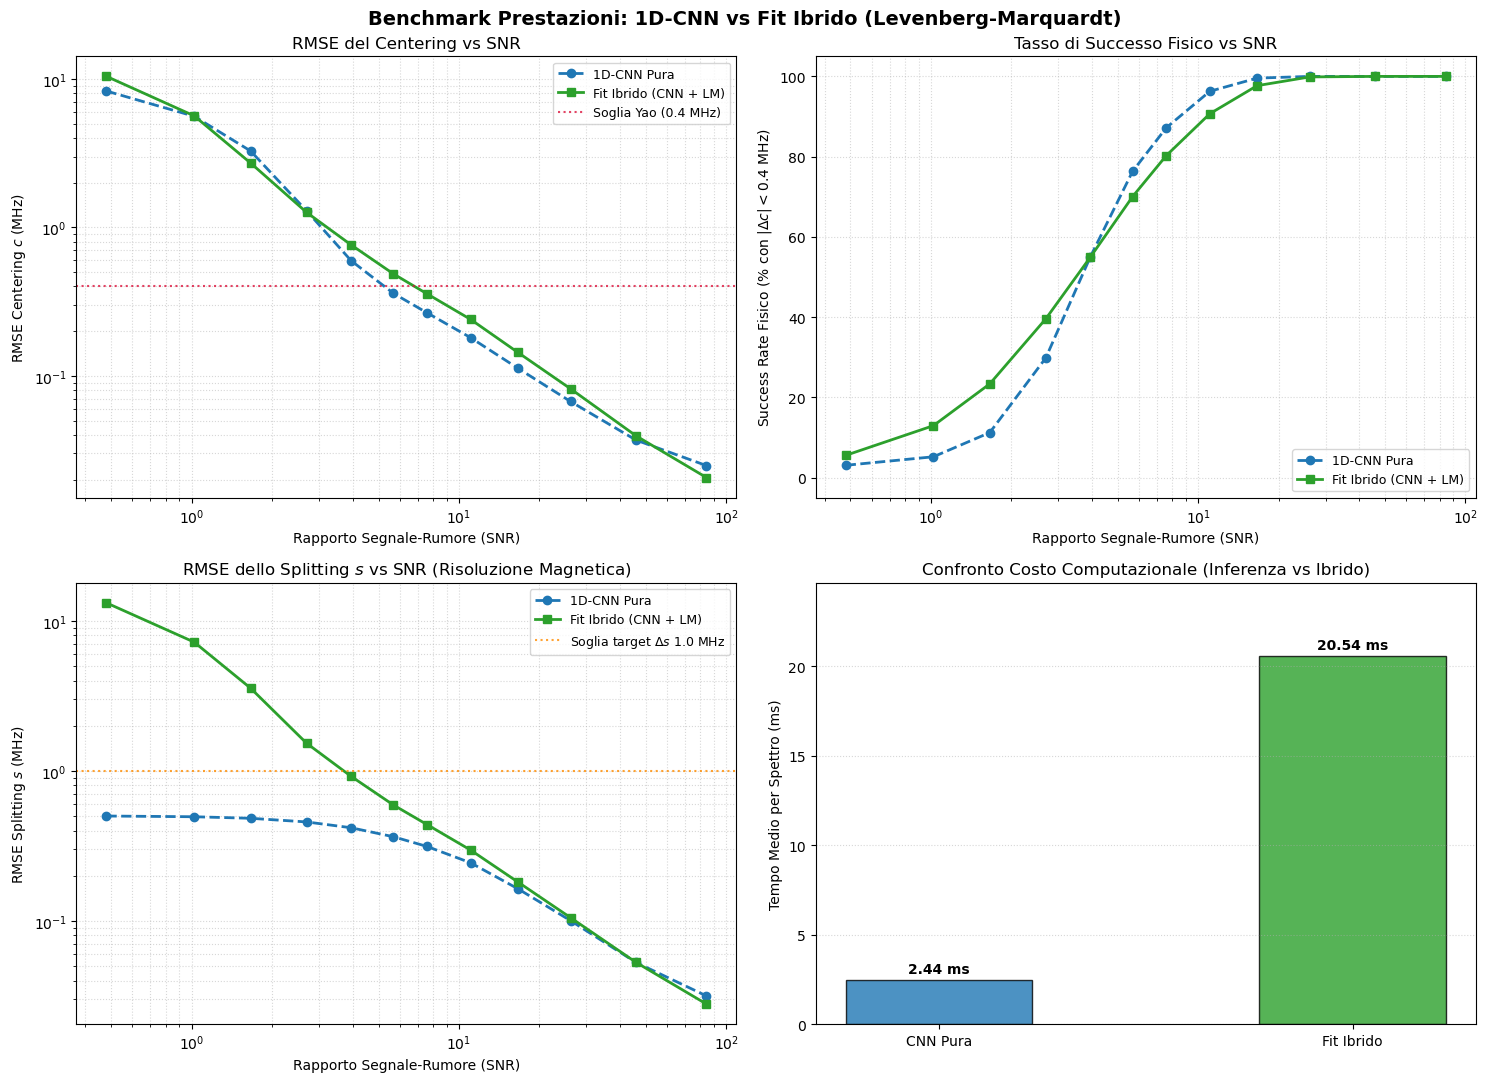

In [2]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================================================================
# 1. SCANSIONE DEI CSV PER MODEL (CNN) E HYBRID
# =========================================================================
dir_model_base = os.path.abspath("../benchmarks/10k/model")
dir_hybrid_base = os.path.abspath("../benchmarks/10k/hybrid")

K_points = 335          # Numero di canali di sweep (DOPPIA DENSITÀ: 335 punti)
delta_sweep_mhz = 200.0 # Finestra fisica [2.75, 2.95] GHz
soglia_successo_mhz = 0.4 # Soglia fisica Yao et al. (~5 K)

def parse_benchmark_folder(folder_path, method_label):
    files = glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True)
    records = []
    
    for filepath in files:
        match_c = re.search(r"contrast=([\d\.]+)", filepath)
        match_n = re.search(r"Nph(\d+)", filepath)
        if not (match_c and match_n):
            continue
            
        c_val = float(match_c.group(1))
        n_ph = float(match_n.group(1))
        
        # Calcolo analitico SNR di singolo canale
        snr_val = c_val * np.sqrt(n_ph / K_points)
        
        try:
            df = pd.read_csv(filepath, comment="#")
        except Exception:
            continue
            
        n_total = len(df)
        if n_total == 0:
            continue
            
        # Filtriamo eventuali fit non convergenti (per la CNN converged è sempre True)
        valid = df[df["converged"] == 1] if "converged" in df.columns else df
        n_conv = len(valid)
        
        if n_conv > 0:
            # Errori in MHz
            err_c_mhz = valid["err_c_norm"] * delta_sweep_mhz
            err_s_mhz = valid["err_s_norm"] * delta_sweep_mhz
            
            rmse_c = np.sqrt(np.mean(err_c_mhz**2))
            rmse_s = np.sqrt(np.mean(err_s_mhz**2))
            mae_c = np.mean(err_c_mhz)
            mae_s = np.mean(err_s_mhz)
            
            # Tasso di successo fisico Yao (|Δc| < 0.4 MHz)
            phys_success = (np.sum(err_c_mhz < soglia_successo_mhz) / n_total) * 100.0
            mean_time_ms = valid["fit_time_sec"].mean() * 1e3
        else:
            rmse_c, rmse_s = np.nan, np.nan
            mae_c, mae_s = np.nan, np.nan
            phys_success = 0.0
            mean_time_ms = np.nan
            
        records.append({
            "method": method_label,
            "contrast": c_val,
            "n_photons": n_ph,
            "snr": snr_val,
            "rmse_c_mhz": rmse_c,
            "rmse_s_mhz": rmse_s,
            "mae_c_mhz": mae_c,
            "mae_s_mhz": mae_s,
            "phys_success_rate": phys_success,
            "time_per_spectrum_ms": mean_time_ms
        })
        
    return pd.DataFrame(records)

# Caricamento ed estrazione
df_model = parse_benchmark_folder(dir_model_base, "CNN Pura")
df_hybrid = parse_benchmark_folder(dir_hybrid_base, "Fit Ibrido")

df_all = pd.concat([df_model, df_hybrid], ignore_index=True)
print(f"Configurazioni caricate: CNN Pura = {len(df_model)} | Fit Ibrido = {len(df_hybrid)}")

# =========================================================================
# 2. GENERAZIONE GRAFICI COMPARATIVI (CNN vs IBRIDO)
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(
    "Benchmark Prestazioni: 1D-CNN vs Fit Ibrido (Levenberg-Marquardt)",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

method_styles = {
    "CNN Pura": {"color": "#1f77b4", "marker": "o", "ls": "--", "label": "1D-CNN Pura"},
    "Fit Ibrido": {"color": "#2ca02c", "marker": "s", "ls": "-", "label": "Fit Ibrido (CNN + LM)"}
}

# -------------------------------------------------------------------------
# PANNELLO 1: RMSE Centering c vs SNR (log-log)
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
for method in ["CNN Pura", "Fit Ibrido"]:
    sub = df_all[df_all["method"] == method].sort_values(by="snr")
    if len(sub) > 0:
        grouped = sub.groupby(
            pd.qcut(sub["snr"], q=min(12, len(sub)), duplicates="drop")
        )[["snr", "rmse_c_mhz"]].mean()
        
        cfg = method_styles[method]
        ax1.plot(
            grouped["snr"], grouped["rmse_c_mhz"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"]
        )

ax1.axhline(soglia_successo_mhz, color="crimson", linestyle=":", alpha=0.8, label=f"Soglia Yao ({soglia_successo_mhz} MHz)")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax1.set_ylabel("RMSE Centering $c$ (MHz)")
ax1.set_title("RMSE del Centering vs SNR")
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 2: Tasso di Successo Fisico (|Δc| < 0.4 MHz) vs SNR
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
for method in ["CNN Pura", "Fit Ibrido"]:
    sub = df_all[df_all["method"] == method].sort_values(by="snr")
    if len(sub) > 0:
        grouped = sub.groupby(
            pd.qcut(sub["snr"], q=min(12, len(sub)), duplicates="drop")
        )[["snr", "phys_success_rate"]].mean()
        
        cfg = method_styles[method]
        ax2.plot(
            grouped["snr"], grouped["phys_success_rate"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"]
        )

ax2.set_xscale("log")
ax2.set_ylim(-5, 105)
ax2.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax2.set_ylabel(f"Success Rate Fisico (% con $|\\Delta c| < {soglia_successo_mhz}$ MHz)")
ax2.set_title("Tasso di Successo Fisico vs SNR")
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
ax2.legend(fontsize=9, loc="lower right")

# -------------------------------------------------------------------------
# PANNELLO 3: RMSE Splitting s vs SNR (Magnetometria)
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
for method in ["CNN Pura", "Fit Ibrido"]:
    sub = df_all[df_all["method"] == method].sort_values(by="snr")
    if len(sub) > 0:
        grouped = sub.groupby(
            pd.qcut(sub["snr"], q=min(12, len(sub)), duplicates="drop")
        )[["snr", "rmse_s_mhz"]].mean()
        
        cfg = method_styles[method]
        ax3.plot(
            grouped["snr"], grouped["rmse_s_mhz"],
            marker=cfg["marker"], lw=2.0, ls=cfg["ls"], color=cfg["color"],
            label=cfg["label"]
        )

ax3.axhline(1.0, color="darkorange", linestyle=":", alpha=0.8, label="Soglia target $\\Delta s$ 1.0 MHz")
ax3.set_xscale("log")
ax3.set_yscale("log")
ax3.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax3.set_ylabel("RMSE Splitting $s$ (MHz)")
ax3.set_title("RMSE dello Splitting $s$ vs SNR (Risoluzione Magnetica)")
ax3.grid(True, which="both", linestyle=":", alpha=0.5)
ax3.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 4: Confronto Costo Computazionale (Tempo per spettro)
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
times_summary = df_all.groupby("method")["time_per_spectrum_ms"].mean()

methods_ordered = ["CNN Pura", "Fit Ibrido"]
vals = [times_summary.get(m, 0.0) for m in methods_ordered]
bar_colors = [method_styles[m]["color"] for m in methods_ordered]

bars = ax4.bar(methods_ordered, vals, color=bar_colors, alpha=0.8, edgecolor="black", width=0.45)

for bar, val in zip(bars, vals):
    ax4.text(
        bar.get_x() + bar.get_width() / 2.0,
        val + max(vals) * 0.02,
        f"{val:.2f} ms",
        ha="center",
        fontweight="bold",
        fontsize=10
    )

ax4.set_ylabel("Tempo Medio per Spettro (ms)")
ax4.set_title("Confronto Costo Computazionale (Inferenza vs Ibrido)")
ax4.set_ylim(0, max(vals) * 1.2 if len(vals) > 0 and max(vals) > 0 else 1)
ax4.grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()